# Auburn defense: player PPA

Defensive players' PPA (predicted points added, the API's name for EPA) from
`sql/Queries/auburn_defense_player_ppa.sql` and `sql/Queries/sec_linebacker_ppa.sql`.

PPA here is the **offense's** PPA on the plays each defender made (tackles, sacks,
INTs, pass breakups, hurries, forced/recovered fumbles), so **lower is better**.
The y-axes are flipped so better players sit higher.

Tackle PPA is biased by position: safeties and corners often tackle after a
completion has already gained yards, so compare players within a position group.
Season, team and minimum plays are set in each query's `params`.

In [1]:
import os
from pathlib import Path

import pandas as pd
from dotenv import load_dotenv
from sqlalchemy import create_engine
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# project root = the folder containing .env (works from notebooks/ or the root)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / ".env").exists())
load_dotenv(ROOT / ".env")

engine = create_engine(
    f"postgresql+psycopg2://{os.environ['POSTGRES_USER']}:{os.environ['POSTGRES_PASSWORD']}"
    f"@localhost:5432/{os.environ['POSTGRES_DB']}"
)

def read_query(name):
    # run a sql/Queries file; "%" is doubled because psycopg2 treats it as a
    # parameter marker (the defense queries use LIKE '%...')
    sql = (ROOT / "sql" / "Queries" / name).read_text()
    return pd.read_sql(sql.replace("%", "%%"), engine)

# chart colors: categorical slots 1-3 (stay distinguishable for colorblind
# readers when all three appear together), plus text and gray tones
BLUE, ORANGE, AQUA = '#2a78d6', '#eb6834', '#1baf7a'
SURFACE, INK, INK_2, MUTED = '#fcfcfb', '#0b0b0b', '#52514e', '#b8b6ae'
plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE,
    'axes.edgecolor': MUTED, 'axes.labelcolor': INK_2,
    'xtick.color': INK_2, 'ytick.color': INK_2,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titlecolor': INK, 'axes.titlesize': 13, 'axes.titleweight': 'bold',
})

In [2]:
aub = read_query("auburn_defense_player_ppa.sql")
aub

,player,jersey,pos,games,plays,avg_ppa,vs_team_avg,tackles,solo_tackles,tackle_avg_ppa,...,stops,stop_pct,sacks,ints,pbus,hurries,forced_fumbles,fumble_recoveries,havoc_plays,havoc_avg_ppa
0,Elijah Melendez,9,LB,4,37,-0.020,-0.068,32,22,0.041,...,22,68.8,1,0,3,2,0,0,9,-0.678
1,Xavier Atkins,17,LB,4,28,-0.436,-0.483,25,22,-0.330,...,18,72.0,3,0,0,3,0,0,7,-1.123
2,Kaleb Harris,8,S,4,26,0.410,0.363,25,19,0.634,...,8,32.0,0,0,0,0,0,1,0,NaN
3,Eric Winters,5,S,4,25,-0.079,-0.127,24,20,0.134,...,11,45.8,0,0,0,0,1,0,2,-3.159
4,Cody Sigler,94,DL,4,17,-0.245,-0.292,16,13,-0.195,...,13,81.3,0,0,1,0,0,0,3,-0.642
5,Dallas Walker IV,35,DL,4,15,-0.704,-0.751,13,7,-0.209,...,10,76.9,0,0,1,1,0,0,3,-0.669
6,Bryce Deas,16,LB,3,14,-0.067,-0.114,13,8,0.226,...,8,61.5,0,0,1,0,0,0,1,-3.880
7,Jared Smith,41,EDGE,4,12,-0.716,-0.763,10,6,-0.171,...,9,90.0,0,1,0,1,0,0,2,-2.757
8,Andre Jordan Jr.,22,CB,4,12,0.174,0.127,8,7,1.614,...,0,0.0,0,2,2,0,0,0,4,-2.706
9,Jourdin Crawford,95,DL,4,12,0.107,0.060,12,8,0.107,...,8,66.7,1,0,0,0,0,0,1,-0.630


In [3]:
lbs = read_query("sec_linebacker_ppa.sql")
lbs

,player,team,jersey,pos,games,plays,plays_per_game,avg_ppa,ppa_rank,vs_team_avg,...,stop_pct,stop_rank,sacks,ints,pbus,hurries,forced_fumbles,fumble_recoveries,havoc_plays,team_tackler_pct
0,Sam Greene,Kentucky,2,LB,3,12,4.0,-1.315,1,-1.354,...,70.0,12,0,1,1,0,0,0,3,91.8
1,Jayden Woods,Florida,0,LB,4,19,4.8,-0.615,2,-0.682,...,88.9,2,4,0,0,1,0,0,7,91.9
2,Alex Afari Jr.,Kentucky,9,LB,2,12,6.0,-0.577,3,-0.615,...,50.0,37,0,0,1,1,0,0,1,91.8
3,Raylen Wilson,Georgia,5,LB,3,14,4.7,-0.560,4,-0.261,...,92.3,1,0,0,0,1,0,0,3,94.5
4,Whit Weeks,LSU,7,LB,4,26,6.5,-0.532,5,-0.368,...,77.3,3,0,0,1,3,0,0,5,95.6
5,Chris Cole,Georgia,9,LB,4,18,4.5,-0.526,6,-0.227,...,68.8,14,2,0,1,0,0,1,5,94.5
6,Xavier Atkins,Auburn,17,LB,4,28,7.0,-0.436,7,-0.483,...,72.0,9,3,0,0,3,0,0,7,93.8
7,Justin Williams,Georgia,19,LB,4,14,3.5,-0.406,8,-0.107,...,69.2,13,1,0,0,1,0,0,2,94.5
8,QB Reese,Alabama,36,LB,3,12,4.0,-0.406,8,-0.358,...,75.0,6,0,0,0,0,0,0,1,83.4
9,Luke Metz,Alabama,4,LB,3,28,9.3,-0.401,10,-0.352,...,62.5,23,0,1,0,3,0,0,1,83.4


## Auburn defenders: plays made vs. average PPA

Color = position group, shape = position within the group. The dashed line is
Auburn's PPA allowed per play on all its defensive plays.

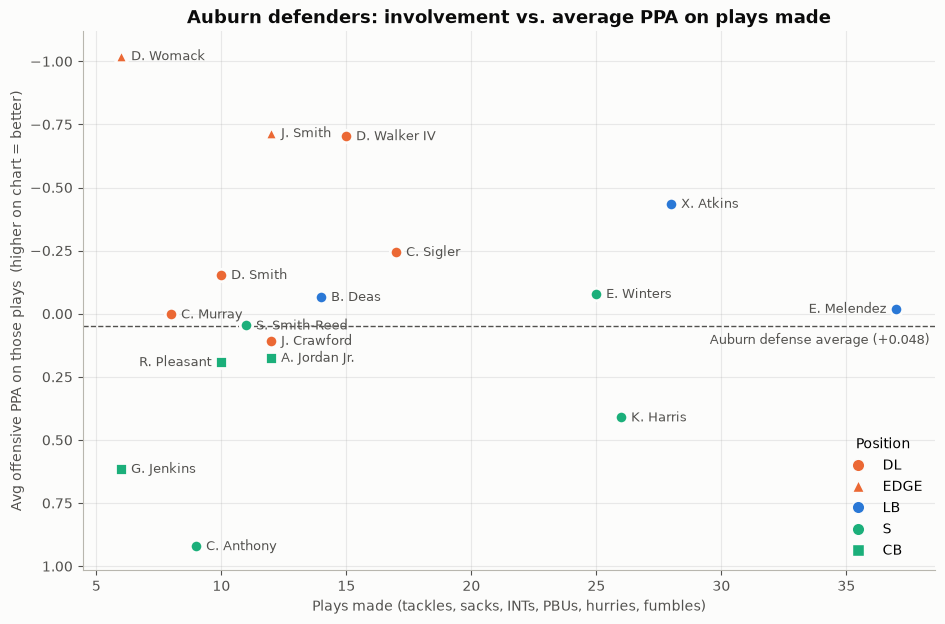

In [4]:
# position -> (group color, marker, label); grouping keeps the chart to three colors
POS_STYLE = {
    'DL':   (ORANGE, 'o', 'DL'),
    'EDGE': (ORANGE, '^', 'EDGE'),
    'LB':   (BLUE,   'o', 'LB'),
    'S':    (AQUA,   'o', 'S'),
    'CB':   (AQUA,   's', 'CB'),
}
team_avg = (aub['avg_ppa'] - aub['vs_team_avg']).iloc[0]

fig, ax = plt.subplots(figsize=(11, 7))
for pos, (color, marker, label) in POS_STYLE.items():
    d = aub[aub['pos'] == pos]
    ax.scatter(d['plays'], d['avg_ppa'], s=80, c=color, marker=marker,
               edgecolors=SURFACE, linewidths=2, zorder=3)
other = aub[~aub['pos'].isin(POS_STYLE)]
ax.scatter(other['plays'], other['avg_ppa'], s=80, c=MUTED, edgecolors=SURFACE, linewidths=2, zorder=3)

# label every player as "F. Last"; LABEL_LEFT puts a label on the left of its
# dot where the right side is crowded or past the edge of the chart
LABEL_LEFT = {'Elijah Melendez', 'Rayshawn Pleasant'}
for _, r in aub.iterrows():
    first, last = r['player'].split(' ', 1)
    left = r['player'] in LABEL_LEFT
    ax.annotate(f'{first[0]}. {last}', (r['plays'], r['avg_ppa']),
                xytext=(-7 if left else 7, -3), textcoords='offset points',
                ha='right' if left else 'left', fontsize=9, color=INK_2)

ax.axhline(team_avg, color=INK_2, lw=1, ls='--', zorder=1)
ax.annotate(f'Auburn defense average ({team_avg:+.3f})', (ax.get_xlim()[1], team_avg),
            xytext=(-4, -13), textcoords='offset points', ha='right', fontsize=9, color=INK_2)

ax.invert_yaxis()   # lower PPA = better, so better players sit higher
ax.set_xlabel('Plays made (tackles, sacks, INTs, PBUs, hurries, fumbles)')
ax.set_ylabel('Avg offensive PPA on those plays  (higher on chart = better)')
ax.set_title('Auburn defenders: involvement vs. average PPA on plays made')
ax.grid(alpha=0.25)
ax.legend(handles=[Line2D([], [], ls='', marker=m, markersize=9, markerfacecolor=c,
                          markeredgecolor=SURFACE, label=l)
                   for c, m, l in POS_STYLE.values()],
          title='Position', loc='lower right', frameon=False)
plt.show()

## Auburn linebackers vs. the rest of the SEC

Every SEC linebacker with at least 10 plays made. Plays per game evens out
players who missed a game. Dotted lines are the medians of all SEC linebackers.

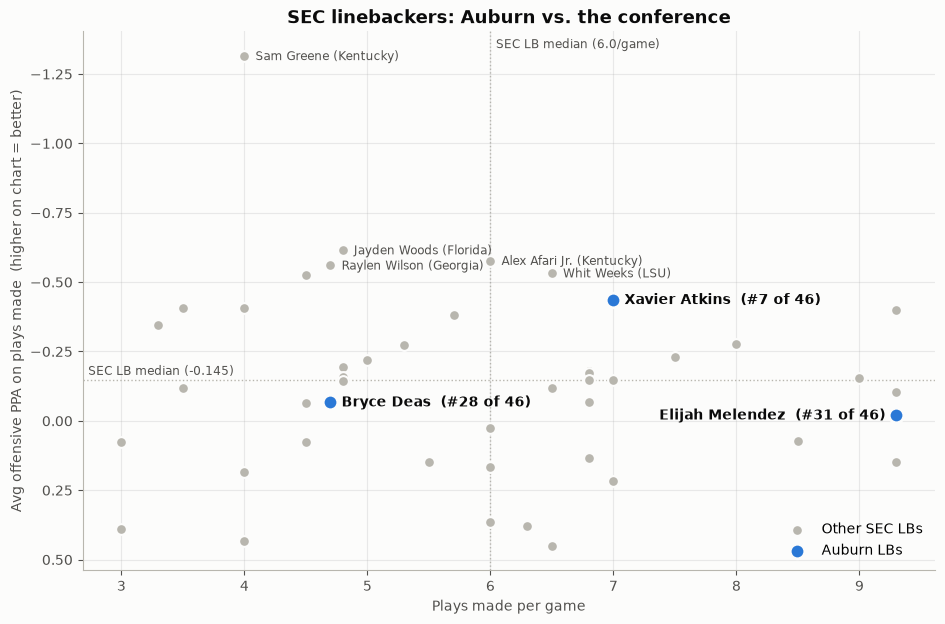

In [5]:
is_aub = lbs['team'] == 'Auburn'
others, mine = lbs[~is_aub], lbs[is_aub]

fig, ax = plt.subplots(figsize=(11, 7))
ax.scatter(others['plays_per_game'], others['avg_ppa'], s=60, c=MUTED,
           edgecolors=SURFACE, linewidths=1.5, zorder=2, label='Other SEC LBs')
ax.scatter(mine['plays_per_game'], mine['avg_ppa'], s=110, c=BLUE,
           edgecolors=SURFACE, linewidths=2, zorder=3, label='Auburn LBs')

med_x, med_y = lbs['plays_per_game'].median(), lbs['avg_ppa'].median()
ax.axvline(med_x, color=MUTED, lw=1, ls=':', zorder=1)
ax.axhline(med_y, color=MUTED, lw=1, ls=':', zorder=1)

# label Auburn's LBs, plus the five best other LBs for reference; points in the
# right fifth of the chart get their label on the left so it stays on the chart
x_left_from = lbs['plays_per_game'].min() + 0.8 * (lbs['plays_per_game'].max() - lbs['plays_per_game'].min())
def label(r, text, **kw):
    left = r['plays_per_game'] > x_left_from
    ax.annotate(text, (r['plays_per_game'], r['avg_ppa']), xytext=(-8 if left else 8, -3),
                textcoords='offset points', ha='right' if left else 'left', **kw)
for _, r in mine.iterrows():
    label(r, f"{r['player']}  (#{r['ppa_rank']} of {len(lbs)})", fontsize=10, color=INK, weight='bold')
for _, r in others.nsmallest(5, 'avg_ppa').iterrows():
    label(r, f"{r['player']} ({r['team']})", fontsize=8.5, color=INK_2)

ax.annotate(f'SEC LB median ({med_x:.1f}/game)', (med_x, 1), xycoords=('data', 'axes fraction'),
            xytext=(4, -12), textcoords='offset points', fontsize=8.5, color=INK_2)
ax.annotate(f'SEC LB median ({med_y:+.3f})', (0, med_y), xycoords=('axes fraction', 'data'),
            xytext=(4, 4), textcoords='offset points', fontsize=8.5, color=INK_2)

ax.invert_yaxis()   # lower PPA = better, so better players sit higher
ax.set_xlabel('Plays made per game')
ax.set_ylabel('Avg offensive PPA on plays made  (higher on chart = better)')
ax.set_title('SEC linebackers: Auburn vs. the conference')
ax.grid(alpha=0.25)
ax.legend(loc='lower right', frameon=False)
plt.show()

In [6]:
# Auburn's LBs ranked among all SEC linebackers in the query (`of` = how many)
mine[['player', 'games', 'plays', 'plays_per_game', 'avg_ppa', 'ppa_rank', 'vs_team_avg', 'vs_team_rank',
      'tfl', 'stop_pct', 'stop_rank', 'havoc_plays']].assign(of=len(lbs))

,player,games,plays,plays_per_game,avg_ppa,ppa_rank,vs_team_avg,vs_team_rank,tfl,stop_pct,stop_rank,havoc_plays,of
6,Xavier Atkins,4,28,7.0,-0.436,7,-0.483,5,7,72.0,9,7,46
27,Bryce Deas,3,14,4.7,-0.067,28,-0.114,26,0,61.5,26,1,46
30,Elijah Melendez,4,37,9.3,-0.020,31,-0.068,30,6,68.8,14,9,46
